# STK Asistanı — Dataset and preprocessing

This notebook documents **every data source, every cleaning step and every transformation** that turns raw
downloads into the project's final dataset, `data/final/country_crisis_dataset.csv` (one row per country),
and the training data of the classifiers.

| # | Source | Publisher (type) | Used for |
|---|---|---|---|
| 1 | HumSet | DEEP / Data Friendly Space (Apache-2.0) | training text for the sector and casualty classifiers |
| 2 | UCDP GED 26.1 + candidate 2026 | Uppsala University (academic) | conflict and civilian deaths, monthly trends |
| 3 | Tech for Palestine | Gaza Ministry of Health data (open, volunteer-maintained) | Palestine casualties, starvation deaths |
| 4 | Global Hunger Index 2026 | Concern Worldwide & Welthungerhilfe (NGOs) | hunger |
| 5 | IFRC GO | Red Cross / Red Crescent movement | active appeals, national societies |
| 6 | OECD DAC2A | OECD (donor-reported statistics) | humanitarian aid per recipient |
| 7 | USGS, NASA EONET | science agencies | natural-hazard alerts |
| 8 | 18 RSS feeds | 15 independent outlets + BBC/Guardian/NYT (comparison only) | live news |
| 9 | Natural Earth | public domain | country shapes, population |

No UN data is used.

In [1]:
import sys, json, ast
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import features
from src.config import HUMSET, PROCESSED, LIVE, SECTORS
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## A. Training data — HumSet

**Raw:** 148,621 text excerpts from humanitarian reports (EN/FR/ES), annotated by experts with sectors and
analytical "pillars". **Goal:** a multi-label classifier that tags live news with humanitarian sectors.

In [2]:
raw = pd.concat([pd.read_json(HUMSET / f"{s}.jsonl", lines=True, dtype=False).assign(split=s)
                 for s in ("train", "validation", "test")], ignore_index=True)
raw["sectors"] = raw["sectors"].map(lambda s: ast.literal_eval(s) if isinstance(s, str) else s)
print("rows:", len(raw)); print(raw["split"].value_counts().to_dict()); print(raw["lang"].value_counts().to_dict())
raw[["lang", "excerpt", "sectors"]].head(3)

rows: 148621
{'train': 117435, 'validation': 16039, 'test': 15147}
{'en': 91134, 'fr': 30268, 'es': 27219}


,lang,excerpt,sectors
0,fr,Le groupe Maï-Maï Léopard actif dans la région...,[]
1,en,"[February 12, Homs] The Homs governorate has g...",[Livelihoods]
2,en,Updated Sector Situation The COVID-19 pandemic...,[Health]


### A.1 Cleaning

In [3]:
steps = []
steps.append(("raw excerpts", len(raw)))
no_sector = raw["sectors"].map(len) == 0
steps.append(("drop: no sector label (annotators tagged only pillars)", int(no_sector.sum())))
short = raw["excerpt"].fillna("").str.strip().str.len() <= 20
steps.append(("drop: excerpt <= 20 characters", int((short & ~no_sector).sum())))
dups = raw["excerpt"].duplicated()
steps.append(("info: duplicated excerpts (kept, official split preserved)", int(dups.sum())))
clean = raw[~no_sector & ~short].copy()
steps.append(("clean excerpts", len(clean)))
pd.DataFrame(steps, columns=["step", "rows"])

,step,rows
0,raw excerpts,148621
1,drop: no sector label (annotators tagged only ...,33445
2,drop: excerpt <= 20 characters,8
3,"info: duplicated excerpts (kept, official spli...",2057
4,clean excerpts,115168


### A.2 Label mapping

HumSet's 11 sectors are mapped to the project's 10-sector taxonomy. *Cross* (cross-sectoral) is dropped,
because it is not an area of work an NGO can choose. Labels are then binarised (multi-label).

mapping: {'Food Security': 'food', 'Health': 'health', 'WASH': 'wash', 'Shelter': 'shelter', 'Education': 'education', 'Protection': 'protection', 'Nutrition': 'nutrition', 'Livelihoods': 'livelihoods', 'Agriculture': 'agriculture', 'Logistics': 'logistics'}
labels per excerpt (mean): 1.11


imbalance largest/smallest: 13.3 x  -> class weights + per-class thresholds


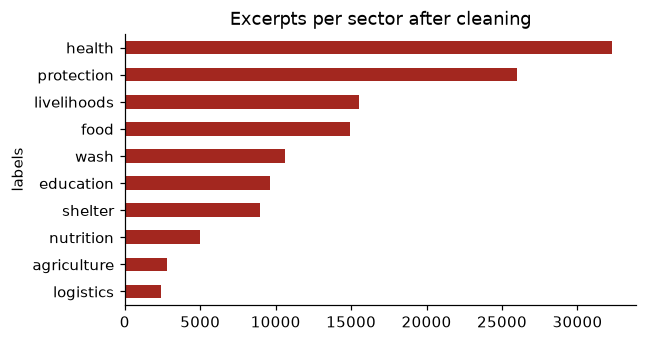

In [4]:
mapping = {v[2]: k for k, v in SECTORS.items()}
clean["labels"] = clean["sectors"].map(lambda xs: [mapping[x] for x in xs if x in mapping])
print("mapping:", mapping)
print("labels per excerpt (mean):", round(clean["labels"].map(len).mean(), 2))
counts = clean.explode("labels")["labels"].value_counts()
ax = counts.sort_values().plot.barh(figsize=(6, 3.2), color="#a3271f", title="Excerpts per sector after cleaning")
print("imbalance largest/smallest:", round(counts.max() / counts.min(), 1), "x  -> class weights + per-class thresholds")

## B. Crisis indicators (one row per country)

### B.1 Countries and population — Natural Earth

177 countries with ISO-3 codes and a population estimate, used as the **spine** of the dataset and for all per-capita rates.

In [5]:
countries = pd.read_parquet(PROCESSED / "countries.parquet").set_index("iso3")
print(len(countries), "countries; population missing:", int(countries["pop_est"].isna().sum()))
countries[["name", "region", "pop_est"]].head()

177 countries; population missing: 0


,name,region,pop_est
iso3,,,
FJI,Fiji,Oceania,889953.0
TZA,Tanzania,Africa,58005463.0
ESH,W. Sahara,Africa,603253.0
CAN,Canada,Americas,37589262.0
USA,United States of America,Americas,328239523.0


### B.2 Conflict deaths — UCDP

Event-level data (one row per violent event). Cleaning steps:
1. merge the final release (to 2025) with the 2026 monthly *candidate* releases, de-duplicate on event id;
2. harmonise country names to ISO-3;
3. **re-assign Gaza and West Bank events to Palestine** — UCDP codes them under Israel;
4. aggregate to country: deaths and civilian deaths in the last 36 months, monthly series for trends.

In [6]:
u = pd.read_parquet(PROCESSED / "ucdp_events.parquet")
print("events:", len(u), "| period:", u["date_start"].min(), "->", u["date_start"].max())
u["iso3"] = features.to_iso(u["country"], features.name_lookup())
print("unmatched country names:", sorted(set(u.loc[u["iso3"].isna(), "country"])))
moved = u["adm_1"].fillna("").str.contains("Gaza|West Bank", case=False)
print(f"events re-assigned from Israel to Palestine: {moved.sum():,} ({u.loc[moved, 'best'].sum():,} deaths)")
u.loc[moved, "iso3"] = "PSE"
u[["date_start", "country", "adm_1", "side_a", "side_b", "best", "deaths_civilians"]].sample(4, random_state=1)

events:

 210115 | period: 2016-01-01 -> 2026-08-31
unmatched country names: ['Bahrain', 'Malta']
events re-assigned from Israel to Palestine: 8,478 (63,938 deaths)


,date_start,country,adm_1,side_a,side_b,best,deaths_civilians
164860,2024-12-08,Sudan,Khartoum state,Government of Sudan,RSF,28,28
63129,2020-09-27,Azerbaijan,Geranboy rayon,Government of Azerbaijan,Republic of Artsakh,5,5
45188,2019-05-18,India,Jammu and Kashmir state,Government of India,Kashmir insurgents,1,0
28478,2017-03-16,Afghanistan,Logar province,Government of Afghanistan,Taleban,0,0


### B.3 Palestine — Gaza Ministry of Health (via Tech for Palestine)

UCDP verifies deaths case by case through media reports and undercounts where journalists are killed and access
is blocked. For Palestine the Ministry of Health is the **primary source**. Comparison:

In [7]:
s = json.loads((LIVE / "t4p_summary.json").read_text(encoding="utf-8"))
daily = pd.read_parquet(PROCESSED / "t4p_daily.parquet")
wb = pd.read_parquet(PROCESSED / "t4p_west_bank.parquet").ffill().iloc[-1]
ucdp_pse = u[u["iso3"] == "PSE"]
pd.DataFrame({
  "UCDP (verified events)": [ucdp_pse["best"].sum(), ucdp_pse["deaths_civilians"].sum()],
  "Gaza MoH + West Bank": [s["killed"]["total"] + daily["famine_cum"].max() + wb["killed_cum"],
                           s["killed"]["children"] + s["killed"]["women"] + wb["killed_children_cum"]],
}, index=["deaths", "civilians (MoH: children + women only = lower bound)"])

,UCDP (verified events),Gaza MoH + West Bank
deaths,63938,75979.0
civilians (MoH: children + women only = lower bound),31135,32919.0


### B.4 Hunger — Global Hunger Index 2026

The Excel release is parsed from the ranking sheet. Cleaning: `"<5"` → 2.5; countries with incomplete data
receive GHI's **provisional category**, used at the range midpoint (e.g. Sudan, South Sudan, Yemen: *alarming*
35–49.9 → 42.45); combined rows (*"Burundi, South Sudan and Yemen"*) are split; names are harmonised.

In [8]:
ghi = pd.read_parquet(PROCESSED / "ghi.parquet")
ghi["iso3"] = features.to_iso(ghi["country"], features.name_lookup())
print(len(ghi), "countries | provisional:", ghi.loc[ghi["ghi_provisional"], "country"].tolist())
print("unmatched names:", ghi.loc[ghi["iso3"].isna(), "country"].tolist())
ghi.sort_values("ghi_2026", ascending=False).head(10)

130 countries | provisional: ['Slovakia', 'Nicaragua', 'Korea (DPR)', 'Lesotho', 'Sudan', 'Burundi', 'South Sudan', 'Yemen']
unmatched names: ['Mauritius', 'Comoros']


,country,ghi_2026,ghi_2018,ghi_provisional,iso3
125,Somalia,47.00,51.1,False,SOM
126,Sudan,42.45,26.0,True,SDN
129,Yemen,42.45,NaN,True,YEM
127,Burundi,42.45,NaN,True,BDI
128,South Sudan,42.45,NaN,True,SSD
124,Dem. Rep. of the Congo,39.50,36.6,False,COD
123,Chad,38.00,38.5,False,TCD
122,Madagascar,36.50,35.7,False,MDG
119,Haiti,34.40,30.4,False,HTI
118,Nigeria,34.30,28.2,False,NGA


### B.5 Red Cross / Red Crescent appeals — IFRC GO

Active appeals (end date after today); appeals without a requested amount are dropped; per country:
requested CHF, % funded, and whether there is a large *Emergency Appeal* (used to recognise a crisis).

In [9]:
app = pd.read_parquet(PROCESSED / "ifrc_appeals.parquet")
print(len(app), "active appeals,", (app["requested"] <= 0).sum(), "without requested amount (dropped)")
app = app[app["requested"] > 0]
app.groupby("type").agg(n=("name", "size"), requested_chf=("requested", "sum"), funded_chf=("funded", "sum"))

164 active appeals, 1 without requested amount (dropped)


,n,requested_chf,funded_chf
type,,,
DREF,128,5.206021e+07,5.188119e+07
Emergency Appeal,35,2.183450e+09,1.080399e+09


### B.6 Humanitarian aid — OECD DAC2A

Humanitarian aid disbursed per recipient (measure 216, all reporting donors, constant USD), mean of the last two
years. **Correction:** Türkiye reports the cost of hosting Syrian refugees *in Türkiye* as humanitarian aid to
Syria. This is a real and very large burden, but it is not aid present inside Syria, so it is excluded
from this measure only.

In [10]:
oe = pd.read_parquet(PROCESSED / "oecd_humanitarian.parquet")
syr = oe[oe["RECIPIENT"] == "SYR"].pivot_table(index="donor", columns="TIME_PERIOD", values="usd") / 1e6
syr.round(0).rename(index={"ALLD": "all donors (USD m)", "TUR": "of which reported by Türkiye (USD m)"})

TIME_PERIOD,2022,2023,2024
donor,,,
all donors (USD m),8042.0,9381.0,7298.0
of which reported by Türkiye (USD m),6242.0,6748.0,5928.0


### B.7 Live news — 18 RSS feeds

Cleaning: HTML stripped, duplicates removed (same URL), date parsed. **Country tagging** uses a gazetteer of
country and crisis place names (e.g. Rafah, El Fasher, Goma). Demonyms are used only if no place is named, so a
report is attributed to the place where people are affected, not to the attacking state.

In [11]:
from src.sources.news import tag_countries
nw = pd.DataFrame(json.loads((LIVE / "news.json").read_text(encoding="utf-8"))).drop_duplicates("id")
print(len(nw), "unique items |", f"{(nw['iso3s'].map(len) > 0).mean():.0%} tagged with a country")
display(nw.groupby(["group", "source"]).size().rename("items").to_frame().T)
for s_ in ["Israeli strikes kill 20 in Gaza", "RSF attack El Fasher, Sudan", "South Sudan floods displace thousands"]:
    print(f"{s_!r:45} -> {tag_countries(s_)}")

669 unique items | 74% tagged with a country


group  independent                                                                                                                                         \
source  Africanews Al Jazeera Amnesty International Amu TV Anadolu Agency Ariana News Daily Sabah Dawn MSF Middle East Eye Middle East Monitor Mondoweiss   
items           52         27                    12     11             37          21          50   26  10              20                  57         10   

group                                          western                              
source Radio Dabanga The New Arab Yeni Şafak BBC World New York Times The Guardian  
items             12          121         60        36             58           49

'Israeli strikes kill 20 in Gaza'             -> ['PSE']
'RSF attack El Fasher, Sudan'                 -> ['SDN']
'South Sudan floods displace thousands'       -> ['SSD']


## C. Missing values — how they are handled

Rule: **missing data is never treated as "no need".** Each component is either computed, set to a documented
neutral value, or excluded from the weighted mean for that country.

In [12]:
final = pd.read_csv(ROOT / "data/final/country_crisis_dataset.csv").set_index("iso3")
miss = final[["ucdp_deaths_3y", "ghi_2026", "ifrc_funded_pct", "aid_per_person", "news_independent"]].isna().mean().mul(100).round(0)
rule = {"ucdp_deaths_3y": "UCDP is global: no event = 0 recorded deaths",
        "ghi_2026": "high-income countries are not scored by GHI (no hunger problem); excluded from the mean",
        "ifrc_funded_pct": "no active appeal: funding gap = neutral 0.5 in the UI",
        "aid_per_person": "computed only for recognised crises; elsewhere aid gap = 0",
        "news_independent": "no news = 0 (attention)"}
pd.DataFrame({"% missing": miss, "handling": pd.Series(rule)})

,% missing,handling
ucdp_deaths_3y,0.0,UCDP is global: no event = 0 recorded deaths
ghi_2026,28.0,high-income countries are not scored by GHI (n...
ifrc_funded_pct,57.0,no active appeal: funding gap = neutral 0.5 in...
aid_per_person,90.0,computed only for recognised crises; elsewhere...
news_independent,0.0,no news = 0 (attention)


## D. Normalisation and the final dataset

| component | formula (0–1) |
|---|---|
| civilian harm | civilian deaths per 100k (3 years) / 200, capped |
| conflict intensity | deaths per 100k (3 years) / 500, capped — **linear**: a log scale hid an 84× gap between Palestine and Israel |
| hunger | GHI / 50, capped; Palestine (not in GHI): documented starvation deaths |
| protracted suffering | ½ × worst civilian dimension (killed or starving) + ½ × weighted mean |
| vulnerability | max(hunger level, ongoing violence) — a hazard in a state that copes alone counts 0 |
| acute | max(natural hazard × vulnerability, new IFRC appeal, recent violence) |
| aid gap | aid per person in severe need: $5 → 1, $300 → 0 (log); starvation deaths override budgets |
| worsening | last 3 months vs median of previous 12 and previous quarter; bonus only |

In [13]:
cols = ["name", "ucdp_deaths_3y", "civilian_per100k_3y", "ghi_2026", "aid_per_person", "status",
        "n_civilian_harm", "n_hunger", "n_prot", "n_acute", "n_aid_gap", "silence"]
print(final.shape)
final.sort_values("n_prot", ascending=False)[cols].head(15).round(2)

(177, 38)


,name,ucdp_deaths_3y,civilian_per100k_3y,ghi_2026,aid_per_person,status,n_civilian_harm,n_hunger,n_prot,n_acute,n_aid_gap,silence
iso3,,,,,,,,,,,,
PSE,Palestine,75979.0,702.60,NaN,440.20,easing_ongoing,1.00,1.00,1.00,0.78,0.90,0.61
SDN,Sudan,89846.0,172.75,42.45,36.79,easing_ongoing,0.86,0.85,0.81,0.25,0.51,0.81
SOM,Somalia,10021.0,6.46,47.00,220.80,chronic,0.03,0.94,0.66,0.16,0.07,0.66
SSD,S. Sudan,1972.0,3.53,42.45,211.36,worsening,0.02,0.85,0.57,0.03,0.09,0.57
YEM,Yemen,4949.0,3.48,42.45,116.45,worsening,0.02,0.85,0.57,0.14,0.23,0.35
BDI,Burundi,257.0,1.56,42.45,11.83,stable,0.01,0.85,0.57,0.00,0.79,0.57
COD,Dem. Rep. Congo,18073.0,13.39,39.50,38.11,chronic,0.07,0.79,0.55,0.21,0.50,0.55
TCD,Chad,602.0,0.61,38.00,115.16,stable,0.00,0.76,0.51,0.14,0.23,0.51
HTI,Haiti,4309.0,22.95,34.40,88.18,stable,0.11,0.69,0.49,0.03,0.30,0.41


## E. Sanity checks against domain knowledge

In [14]:
chk = final.loc[["PSE", "SDN", "YEM", "UKR", "ISR", "USA", "MDG"],
                ["name", "deaths_per100k_3y", "civilian_per100k_3y", "ghi_2026", "n_acute", "n_prot", "n_aid_gap", "status"]]
chk.round(2)

,name,deaths_per100k_3y,civilian_per100k_3y,ghi_2026,n_acute,n_prot,n_aid_gap,status
iso3,,,,,,,,
PSE,Palestine,1621.64,702.60,NaN,0.78,1.00,0.90,easing_ongoing
SDN,Sudan,209.86,172.75,42.45,0.25,0.81,0.51,easing_ongoing
YEM,Yemen,16.97,3.48,42.45,0.14,0.57,0.23,worsening
UKR,Ukraine,594.80,17.54,11.60,0.50,0.29,NaN,chronic
ISR,Israel,16.04,8.63,NaN,0.00,0.04,NaN,stable
USA,United States of America,0.00,0.00,NaN,0.00,0.00,NaN,stable
MDG,Madagascar,0.00,0.00,36.50,0.00,0.49,0.56,no_recorded_violence


* **Palestine vs Israel:** 1,622 vs 16 deaths per 100k people; civilian harm 1.0 vs 0.04.
* **Ukraine:** the deadliest war in absolute terms, but 97% of recorded deaths are combatants, so civilian harm is low.
* **USA:** hazards occur but vulnerability is 0, so acute need is 0.
* **Madagascar:** no conflict and no news, but GHI 36.5 (*alarming*), an underfunded cyclone appeal and about $30 of aid per
  person in severe need. This is a *silent* crisis, exactly what the tool is meant to surface.

## F. Model results (from `models/*.json`)

In [15]:
m = json.loads((ROOT / "models/sector_metrics.json").read_text())
p = json.loads((ROOT / "models/pillar_metrics.json").read_text())
display(pd.DataFrame([{"model": r["model"], "micro-F1": r["micro_f1"], "macro-F1": r["macro_f1"]} for r in m["results"]]))
print("macro-F1 by language:", {k: v["macro_f1"] for k, v in m["by_language"].items()})
print("casualty / displacement model:", p["per_class"])

,model,micro-F1,macro-F1
0,keyword baseline,0.5578,0.5392
1,tfidf+logreg (t=0.5),0.7793,0.7439
2,tfidf+logreg (tuned t),0.7795,0.7393


macro-F1 by language: {'en': 0.7462, 'es': 0.6212, 'fr': 0.714}
casualty / displacement model: {'Casualties': 0.627, 'Displacement': 0.745, 'Shock/Event': 0.592, 'Humanitarian Access': 0.593}
